# 矮星系瞬时 SFR 演化

本 notebook 直接读取 `RawData/DwarfGalaxy/fullFB_inflow` 中未经降采样的 Athena++/MACER3D `.athdf` 文件。瞬时 SFR 使用三维球坐标网格上的 `rhodotsf` 计算：

$$\mathrm{SFR}(t)=\sum_{b,k,j,i}\dot{\rho}_{\star,bkji}(t)\,\Delta V_{bkji},$$

其中 $\Delta V=(r_2^3-r_1^3)(\cos\theta_1-\cos\theta_2)(\phi_2-\phi_1)/3$。时间直接读取文件的 `Time` 属性，不由文件编号推算；物理零值会保留在数据表中，检测到的时间缺口会在曲线上断开。绘图纵轴固定为 $0.5\text{--}3.0\,M_\odot\,\mathrm{yr}^{-1}$。

In [11]:
# 单元总注释：定位项目根目录、加载基础配置并导入依赖。
import json
import re
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_project_root(start: Path) -> Path:
    """从当前目录向上寻找 MACNet 项目根目录。"""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / '.config' / 'BaseConfig.json').is_file():
            return candidate
    raise FileNotFoundError(
        f'无法从 {start} 定位项目根目录；请从 MACNet-v1 或其子目录启动 notebook。'
    )


project_root = find_project_root(Path.cwd())
with (project_root / '.config' / 'BaseConfig.json').open(encoding='utf-8') as handle:
    base_config = json.load(handle)

raw_data_root = Path(base_config['raw_data_dir']).expanduser().resolve()
if not raw_data_root.is_dir():
    raise FileNotFoundError(f'配置中的原始数据目录不存在：{raw_data_root}')

sns.set_theme(style='whitegrid', context='notebook')
print(f'Project root: {project_root}')
print(f'Raw data root: {raw_data_root}')

Project root: D:\research\ai+MACERsimulation\MACNet-v1
Raw data root: E:\科研项目与原始数据\ai+MACERsimulation\MACNet-v1\RawData


In [12]:
# 单元总注释：设置数据位置、SFR 单位换算、时间筛选和绘图参数。
DWARF_RUN_RELATIVE_DIR = Path('DwarfGalaxy') / 'fullFB_inflow'
DWARF_DATA_DIR = (raw_data_root / DWARF_RUN_RELATIVE_DIR).resolve()
RUN_NAME = 'dwarf_galaxy_fullFB_inflow'
TARGET_VARIABLE = 'rhodotsf'

# MACER 单位制：质量单位为 2.5e7 Msun，时间单位为 1 Gyr。
MACER_MASS_UNIT_MSUN = 2.5e7
MACER_TIME_UNIT_GYR = 1.0
TO_MSUN_PER_YR = MACER_MASS_UNIT_MSUN / (MACER_TIME_UNIT_GYR * 1.0e9)

TIME_RANGE_GYR = None  # 例如 (2.6, 3.0)；None 表示使用全部 snapshot
SFR_Y_LIMITS = (0.5, 3.0)  # 单位为 Msun/yr
TIME_GAP_FACTOR = 1.5  # 相邻时间差超过典型步长的该倍数时判定为缺帧

if not DWARF_DATA_DIR.is_dir():
    raise FileNotFoundError(f'矮星系数据目录不存在：{DWARF_DATA_DIR}')
if TO_MSUN_PER_YR <= 0.0:
    raise ValueError('SFR 单位换算系数必须为正数。')

print(f'Dwarf data directory: {DWARF_DATA_DIR}')
print(f'SFR conversion: 1 code mass/Gyr = {TO_MSUN_PER_YR:g} Msun/yr')

Dwarf data directory: E:\科研项目与原始数据\ai+MACERsimulation\MACNet-v1\RawData\DwarfGalaxy\fullFB_inflow
SFR conversion: 1 code mass/Gyr = 0.025 Msun/yr


In [13]:
# 单元总注释：定义 Athena++ 变量定位、球坐标体积计算和单帧 SFR 读取函数。
def _decode_attr_strings(values) -> list[str]:
    """把 HDF5 属性中的 bytes 或字符串数组统一转换为字符串列表。"""
    return [value.decode() if isinstance(value, bytes) else str(value) for value in values]


def snapshot_index(path: Path) -> int:
    """从 yuan18.out1.00050.athdf 一类文件名提取数值编号。"""
    match = re.search(r'\.(\d+)\.athdf$', path.name)
    if match is None:
        raise ValueError(f'无法从文件名提取 snapshot 编号：{path.name}')
    return int(match.group(1))


def locate_athena_variable(handle: h5py.File, variable_name: str) -> tuple[str, int]:
    """根据 Athena++ 的 DatasetNames/NumVariables 属性定位变量。"""
    variable_names = _decode_attr_strings(handle.attrs['VariableNames'])
    dataset_names = _decode_attr_strings(handle.attrs['DatasetNames'])
    variable_counts = np.atleast_1d(handle.attrs['NumVariables']).astype(int)
    if len(dataset_names) != len(variable_counts):
        raise ValueError('DatasetNames 与 NumVariables 长度不一致。')
    if variable_name not in variable_names:
        raise KeyError(f'{handle.filename} 不包含变量 {variable_name!r}。')

    global_index = variable_names.index(variable_name)
    offset = 0
    for dataset_name, count in zip(dataset_names, variable_counts):
        if offset <= global_index < offset + count:
            return dataset_name, global_index - offset
        offset += count
    raise ValueError(f'变量 {variable_name!r} 无法映射到任何 Athena++ dataset。')


def build_spherical_cell_volumes(handle: h5py.File) -> np.ndarray:
    """用每个 MeshBlock 的面坐标计算 (block, phi, theta, radius) 单元体积。"""
    coordinates = handle.attrs.get('Coordinates', b'')
    if isinstance(coordinates, bytes):
        coordinates = coordinates.decode()
    if str(coordinates) != 'spherical_polar':
        raise ValueError(f'只支持 spherical_polar 坐标，实际为 {coordinates!r}。')
    if int(handle.attrs.get('MaxLevel', 0)) != 0:
        raise NotImplementedError('当前 notebook 尚不支持含 AMR 层级的体积重建。')

    x1f = np.asarray(handle['x1f'], dtype=np.float64)
    x2f = np.asarray(handle['x2f'], dtype=np.float64)
    x3f = np.asarray(handle['x3f'], dtype=np.float64)
    radial_factor = (x1f[:, 1:] ** 3 - x1f[:, :-1] ** 3) / 3.0
    polar_factor = np.cos(x2f[:, :-1]) - np.cos(x2f[:, 1:])
    azimuthal_factor = x3f[:, 1:] - x3f[:, :-1]
    volumes = (
        azimuthal_factor[:, :, None, None]
        * polar_factor[:, None, :, None]
        * radial_factor[:, None, None, :]
    )
    if not np.all(np.isfinite(volumes)) or np.any(volumes <= 0.0):
        raise ValueError('计算得到的球坐标单元体积包含非有限值或非正值。')
    return volumes


def read_instantaneous_sfr(path: Path, cell_volumes: np.ndarray) -> dict:
    """读取单帧 rhodotsf，并在完整三维网格上做体积积分。"""
    with h5py.File(path, 'r') as handle:
        dataset_name, local_index = locate_athena_variable(handle, TARGET_VARIABLE)
        sfr_density = np.asarray(handle[dataset_name][local_index], dtype=np.float64)
        time_gyr = float(handle.attrs['Time'])
        cycle = int(handle.attrs.get('NumCycles', -1))

    if sfr_density.shape != cell_volumes.shape:
        raise ValueError(
            f'{path.name} 的 {TARGET_VARIABLE} 形状 {sfr_density.shape} 与体积形状 '
            f'{cell_volumes.shape} 不一致。'
        )
    if not np.isfinite(time_gyr):
        raise ValueError(f'{path.name} 的 Time 属性不是有限值。')
    if not np.all(np.isfinite(sfr_density)):
        raise ValueError(f'{path.name} 的 {TARGET_VARIABLE} 包含 NaN 或 Inf。')
    if np.any(sfr_density < 0.0):
        raise ValueError(f'{path.name} 的 {TARGET_VARIABLE} 包含负值。')

    sfr_code_units = float(np.sum(sfr_density * cell_volumes, dtype=np.float64))
    return {
        'run': RUN_NAME,
        'snapshot_file': path.name,
        'snapshot_index': snapshot_index(path),
        'cycle': cycle,
        'time_gyr': time_gyr,
        'sfr_code_units': sfr_code_units,
        'sfr_msun_per_yr': sfr_code_units * TO_MSUN_PER_YR,
    }

In [14]:
# 单元总注释：发现全部原始 snapshot，审计文件编号，并预计算静态三维网格体积。
athdf_files = sorted(DWARF_DATA_DIR.glob('*.athdf'), key=snapshot_index)
if not athdf_files:
    raise RuntimeError(f'{DWARF_DATA_DIR} 中没有找到 .athdf 文件。')

indices = np.asarray([snapshot_index(path) for path in athdf_files], dtype=np.int64)
unique_indices, index_counts = np.unique(indices, return_counts=True)
duplicate_indices = unique_indices[index_counts > 1].tolist()
expected_indices = np.arange(indices.min(), indices.max() + 1, dtype=np.int64)
missing_indices = np.setdiff1d(expected_indices, unique_indices).tolist()
if duplicate_indices:
    raise ValueError(f'发现重复 snapshot 编号：{duplicate_indices}')

with h5py.File(athdf_files[0], 'r') as first_handle:
    cell_volumes = build_spherical_cell_volumes(first_handle)
    target_dataset_name, target_local_index = locate_athena_variable(
        first_handle, TARGET_VARIABLE
    )
    target_shape = tuple(first_handle[target_dataset_name][target_local_index].shape)

if target_shape != cell_volumes.shape:
    raise ValueError(f'首帧目标形状 {target_shape} 与体积形状 {cell_volumes.shape} 不一致。')

print(f'Found {len(athdf_files)} snapshots: {indices.min()} ... {indices.max()}')
print(f'Target field shape: {target_shape}')
print(f'Missing filename indices: {missing_indices if missing_indices else "none"}')

Found 250 snapshots: 50 ... 299
Target field shape: (512, 16, 16, 16)
Missing filename indices: none


In [15]:
# 单元总注释：逐帧读取原始 rhodotsf，计算瞬时 SFR，并审计真实时间轴。
records = []
for file_number, path in enumerate(athdf_files, start=1):
    records.append(read_instantaneous_sfr(path, cell_volumes))
    if file_number % 25 == 0 or file_number == len(athdf_files):
        print(f'[Load raw] {file_number:>4}/{len(athdf_files)} snapshots')

sfr_evolution = (
    pd.DataFrame.from_records(records)
    .sort_values(['time_gyr', 'snapshot_index'], kind='mergesort')
    .reset_index(drop=True)
)
if sfr_evolution['time_gyr'].duplicated().any():
    duplicate_times = sfr_evolution.loc[
        sfr_evolution['time_gyr'].duplicated(keep=False), 'time_gyr'
    ].tolist()
    raise ValueError(f'发现重复模拟时间：{duplicate_times}')

time_diffs = sfr_evolution['time_gyr'].diff()
positive_time_diffs = time_diffs[time_diffs > 0.0]
if positive_time_diffs.empty:
    raise ValueError('无法从 snapshot 建立严格递增的时间轴。')
typical_dt_gyr = float(positive_time_diffs.median())
sfr_evolution['gap_before'] = time_diffs > TIME_GAP_FACTOR * typical_dt_gyr
time_gaps = sfr_evolution.loc[
    sfr_evolution['gap_before'],
    ['snapshot_file', 'snapshot_index', 'time_gyr'],
].copy()
time_gaps['delta_t_gyr'] = time_diffs.loc[time_gaps.index]

if TIME_RANGE_GYR is not None:
    time_min, time_max = map(float, TIME_RANGE_GYR)
    if not np.isfinite([time_min, time_max]).all() or time_min > time_max:
        raise ValueError(f'非法 TIME_RANGE_GYR：{TIME_RANGE_GYR}')
    sfr_evolution = sfr_evolution.loc[
        sfr_evolution['time_gyr'].between(time_min, time_max)
    ].copy()

print(f'Typical output interval: {typical_dt_gyr * 1.0e3:.6g} Myr')
print(f'Detected time gaps: {len(time_gaps)}')
display(time_gaps if not time_gaps.empty else pd.DataFrame({'status': ['no time gaps']}))

[Load raw]   25/250 snapshots
[Load raw]   50/250 snapshots
[Load raw]   75/250 snapshots
[Load raw]  100/250 snapshots
[Load raw]  125/250 snapshots
[Load raw]  150/250 snapshots
[Load raw]  175/250 snapshots
[Load raw]  200/250 snapshots
[Load raw]  225/250 snapshots
[Load raw]  250/250 snapshots
Typical output interval: 2.00009 Myr
Detected time gaps: 1


,snapshot_file,snapshot_index,time_gyr,delta_t_gyr
1,yuan18.out1.00051.athdf,51,2.504,0.004


In [16]:
# 单元总注释：汇总时间覆盖、SFR 范围和零值数量，便于发现异常帧。
summary = pd.Series({
    'run': RUN_NAME,
    'n_snapshots': len(sfr_evolution),
    'time_min_gyr': sfr_evolution['time_gyr'].min(),
    'time_max_gyr': sfr_evolution['time_gyr'].max(),
    'typical_dt_myr': typical_dt_gyr * 1.0e3,
    'sfr_min_msun_per_yr': sfr_evolution['sfr_msun_per_yr'].min(),
    'sfr_median_msun_per_yr': sfr_evolution['sfr_msun_per_yr'].median(),
    'sfr_max_msun_per_yr': sfr_evolution['sfr_msun_per_yr'].max(),
    'zero_sfr_count': int((sfr_evolution['sfr_msun_per_yr'] == 0.0).sum()),
    'missing_filename_count': len(missing_indices),
    'detected_time_gap_count': len(time_gaps),
})
summary.to_frame('value')

,value
run,dwarf_galaxy_fullFB_inflow
n_snapshots,250
time_min_gyr,2.5
time_max_gyr,3.0
typical_dt_myr,2.000093
sfr_min_msun_per_yr,0.0
sfr_median_msun_per_yr,2.437434
sfr_max_msun_per_yr,2.701753
zero_sfr_count,1
missing_filename_count,0


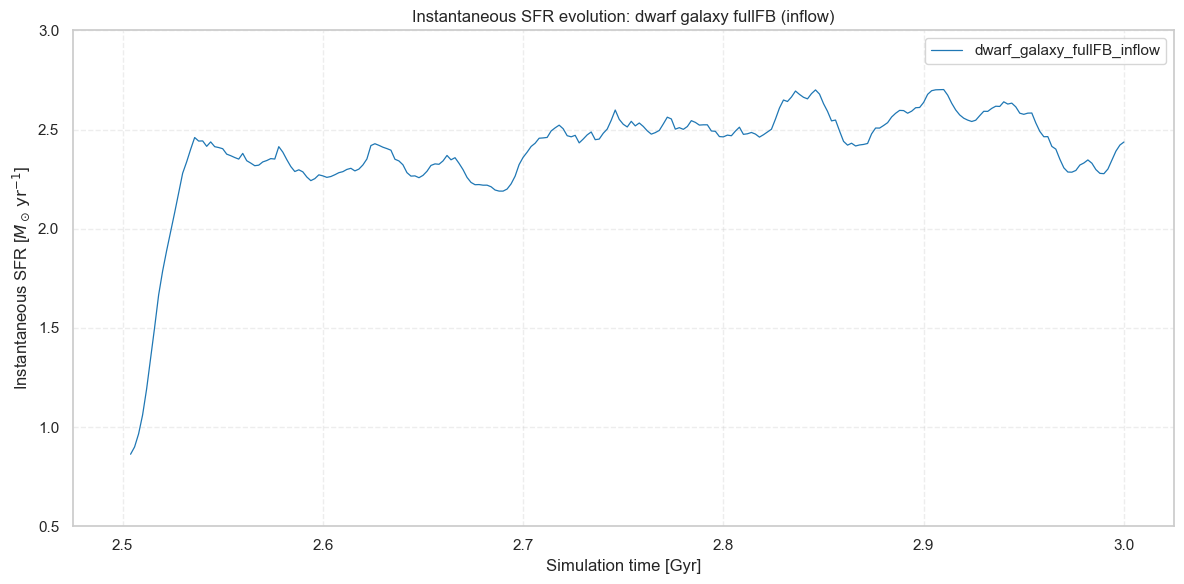

In [17]:
# 单元总注释：绘制矮星系瞬时 SFR；在缺失时间段插入 NaN，避免跨缺帧连线。
plot_times = []
plot_sfr = []
for row_number, row in sfr_evolution.iterrows():
    if bool(row['gap_before']) and plot_times:
        plot_times.append(np.nan)
        plot_sfr.append(np.nan)
    plot_times.append(float(row['time_gyr']))
    plot_sfr.append(float(row['sfr_msun_per_yr']))

fig, axis = plt.subplots(figsize=(12, 6))
axis.plot(plot_times, plot_sfr, linewidth=0.9, color='tab:blue', label=RUN_NAME)
axis.set_ylim(*SFR_Y_LIMITS)
axis.set_xlabel('Simulation time [Gyr]')
axis.set_ylabel(r'Instantaneous SFR [$M_\odot\,\mathrm{yr}^{-1}$]')
axis.set_title('Instantaneous SFR evolution: dwarf galaxy fullFB (inflow)')
axis.grid(True, which='both', linestyle='--', alpha=0.35)
axis.legend(loc='best')
fig.tight_layout()
plt.show()